# Bài 6: Dùng K-Means giảm số màu trong ảnh (nén ảnh)
**Họ tên:** Trần Minh Tấn - **MSSV:** 6451071071

## Khai báo các thư viện

In [1]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os
%matplotlib inline

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Đã khai báo thư viện")

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Đã khai báo thư viện


## Đọc file ảnh cần giảm kích thước và hiển thị ra màn hình
> Ảnh được tải tự động từ Google Drive, không cần upload thủ công.

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Ảnh đang dùng: dog.png


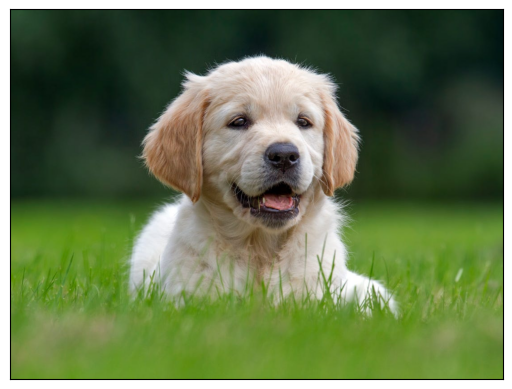

In [2]:
import urllib.request, subprocess, sys

# Tải ảnh trực tiếp từ Google Drive
file_id = "1XCf-DwRg4tqP2_ROPP5SBiN9HwpGC58c"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

def anh_hop_le(ten_file):
    try:
        Image.open(ten_file).verify()
        return True
    except Exception:
        return False

try:
    urllib.request.urlretrieve(url, 'dog.png')
except Exception as e:
    print("Tải bằng urllib lỗi:", e)

if not anh_hop_le('dog.png'):
    # Thử lại bằng gdown
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"])
        import gdown
        gdown.download(id=file_id, output='dog.png', quiet=False)
    except Exception as e:
        print("Tải bằng gdown lỗi:", e)

if anh_hop_le('dog.png'):
    image = Image.open('dog.png').convert('RGB')   # convert('RGB') để bỏ kênh trong suốt (nếu có)
    ten_anh = 'dog.png'
else:
    # Không tải được ảnh từ Drive -> dùng ảnh mẫu của sklearn để vẫn chạy được
    from sklearn.datasets import load_sample_image
    image = Image.fromarray(load_sample_image('china.jpg'))
    image.save('original_img.png')
    ten_anh = 'original_img.png'
    print("CẢNH BÁO: không tải được ảnh từ Drive (kiểm tra quyền chia sẻ 'Bất kỳ ai có đường liên kết').")
    print("Đang dùng ảnh mẫu china.jpg của sklearn.")

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Ảnh đang dùng:", ten_anh)
axes = plt.axes(xticks=[], yticks=[])
axes.imshow(image)

## Chuyển ảnh đọc được thành mảng số và lấy thông tin chiều rộng, cao của ảnh

In [3]:
imarr = np.array(image)
rows = imarr.shape[0]
cols = imarr.shape[1]

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Kích thước mảng ảnh (cao, rộng, sâu):", imarr.shape)
print("Chiều cao (rows):", rows)
print("Chiều rộng (cols):", cols)

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Kích thước mảng ảnh (cao, rộng, sâu): (825, 1100, 3)
Chiều cao (rows): 825
Chiều rộng (cols): 1100


## Biến đổi giá trị màu từ [0...255] về [0...1] và chuyển mảng 3 chiều thành 2 chiều (cao x rộng, sâu)

In [4]:
data = imarr / 255.0   # use 0...1 scale
data = data.reshape(rows * cols, 3)

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("data.shape =", data.shape)

Họ tên: Trần Minh Tấn - MSSV: 6451071071
data.shape = (907500, 3)


## Chạy thuật toán gom cụm với số màu mong muốn là 32, lấy ra mảng biểu diễn hình sau khi gom cụm

In [5]:
kmeans = KMeans(n_clusters=32, max_iter=300)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Đã gom cụm xong, số màu sau khi giảm:", kmeans.n_clusters)
print("new_colors.shape =", new_colors.shape)

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Đã gom cụm xong, số màu sau khi giảm: 32
new_colors.shape = (907500, 3)


## Khôi phục dạng mảng từ 2 chiều thành 3 chiều như ban đầu

In [6]:
img_recolored = new_colors.reshape(imarr.shape)

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("img_recolored.shape =", img_recolored.shape)

Họ tên: Trần Minh Tấn - MSSV: 6451071071
img_recolored.shape = (825, 1100, 3)


## Biểu diễn hình kết quả và so sánh với ảnh gốc ban đầu

Họ tên: Trần Minh Tấn - MSSV: 6451071071


Text(0.5, 1.02, 'Trần Minh Tấn - 6451071071')

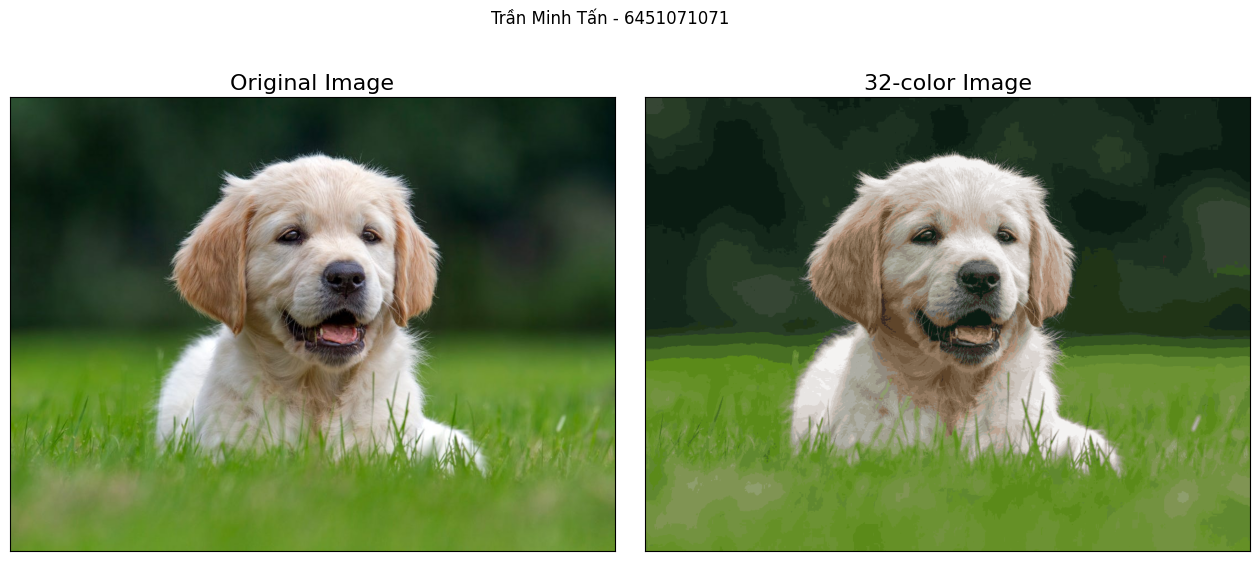

In [7]:
print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(image)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(img_recolored)
ax[1].set_title('32-color Image', size=16);
fig.suptitle("Trần Minh Tấn - 6451071071", y=1.02)

## Lưu hình kết quả xuống đĩa cứng và so sánh dung lượng file

In [8]:
img_recolored = img_recolored * 255
new_img = Image.fromarray(img_recolored.astype(np.uint8))
new_img.save('compressed_img2.png')

# Lưu thêm ảnh gốc ở định dạng PNG để so sánh công bằng (cùng định dạng)
image.save('original_img_png.png')

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
size_goc = os.path.getsize(ten_anh) / 1024
size_goc_png = os.path.getsize('original_img_png.png') / 1024
size_nen = os.path.getsize('compressed_img2.png') / 1024
print(f"Dung lượng file ảnh gốc tải về ({ten_anh})      : {size_goc:.1f} KB")
print(f"Dung lượng ảnh gốc lưu dạng PNG                : {size_goc_png:.1f} KB")
print(f"Dung lượng ảnh sau khi giảm màu (PNG, 32 màu)  : {size_nen:.1f} KB")
print(f"Giảm so với ảnh gốc dạng PNG: {(1 - size_nen / size_goc_png) * 100:.1f}%")
print("Đã lưu file: compressed_img2.png")

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Dung lượng file ảnh gốc tải về (dog.png)      : 69.1 KB
Dung lượng ảnh gốc lưu dạng PNG                : 695.6 KB
Dung lượng ảnh sau khi giảm màu (PNG, 32 màu)  : 182.0 KB
Giảm so với ảnh gốc dạng PNG: 73.8%
Đã lưu file: compressed_img2.png
